<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# PCA Lab: Speed Dating 

_Authors:_ Tim Book, Kiefer Katovich

---

Let's practice principal component analysis (PCA) using the "Speed Dating" dataset collected by Columbia Business school, taken from Kaggle. PCA is often used to simplify data, reduce noise, and find unmeasured latent variables, so it's important to take the time to understand what's going on.

**In this lab, we will:**

- Explore how PCA relates to correlation.
- Use PCA to perform dimensionality reduction.
- Analyze the first principal components and their composition.
- Predict whether or not a speed dater likes reading based on the dater's other likes.

---

### Data Set

The data set we're using for this lab is a subset of this [much more detailed speed dating data set](https://www.kaggle.com/annavictoria/speed-dating-experiment). In particular, this contains no information on the actual speed dating itself (i.e., successes with or opinions of other individuals). 

It also contains no follow-up information where individuals are asked the same questions about themselves again. It only contains information about what an individual enjoys doing, their self-ratings on how desirable they are, and how they think others rate them based on desirability.

The columns present in the data are outlined below:

FieldName|Description
---------|-----------
    subject_id                   |   Unique individual identifier.
    wave                         |   Meetup ID.
    like_sports                  |   Enjoyment of participating in sports.
    like_tvsports                |   Enjoyment of watching sports on TV.
    like_exercise                |   Enjoyment of exercise.
    like_food                    |   Enjoyment of food.
    like_museums                 |   Enjoyment of museums.
    like_art                     |   Enjoyment of art.
    like_hiking                  |   Enjoyment of hiking.
    like_gaming                  |   Enjoyment of playing games.
    like_clubbing                |   Enjoyment of going clubbing/partying.
    like_reading                 |   Enjoyment of reading.
    like_tv                      |   Enjoyment of TV in general.
    like_theater                 |   Enjoyment of the theater (plays, musicals, etc.).
    like_movies                  |   Enjoyment of movies.
    like_concerts                |   Enjoyment of concerts.
    like_music                   |   Enjoyment of music.
    like_shopping                |   Enjoyment of shopping.
    like_yoga                    |   Enjoyment of yoga.
    subjective_attractiveness    |   How attractive they rate themselves.
    subjective_sincerity         |   How sincere they rate themselves.
    subjective_intelligence      |   How intelligent they rate themselves.
    subjective_fun               |   How fun they rate themselves.
    subjective_ambition          |   How ambitious they rate themselves.
    objective_attractiveness     |   Perceived rating others would give them on how attractive they are.
    objective_sincerity          |   Perceived rating others would give them on how sincere they are.
    objective_intelligence       |   Perceived rating others would give them on how intelligent they are.
    objective_fun                |   Perceived rating others would give them on how fun they are.
    objective_ambition           |   Perceived rating others would give them on how ambitious they are.
    
There are 551 subjects total.

---

### Why This Data?
PCA shines when you have "wide" data with many correlated columns and relatively few rows. It's likely that certain columns in this data are correlated (e.g. `like_music` and `like_concerts`). If we were to model this from the start, we're likely to get overfit results. PCA can help us reduce this overfitting by creating new features that are based on the old ones, except de-correlated.

### 1) Load packages.
Put all of your imports in the cell below. Note that this means you may return to this cell later to add libraries as needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, train_test_split

---
### 2) Load and clean the speed dating data.

#### 2a) Load the data

In [2]:
sd = pd.read_csv('../datasets/speed_dating.csv')

In [3]:
sd.head(3)

,subject_id,wave,like_sports,like_tvsports,like_exercise,like_food,like_museums,like_art,like_hiking,like_gaming,...,subjective_attractiveness,subjective_sincerity,subjective_intelligence,subjective_fun,subjective_ambition,objective_attractiveness,objective_sincerity,objective_intelligence,objective_fun,objective_ambition
0,1,1,9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,...,6.0,8.0,8.0,8.0,7.0,NaN,NaN,NaN,NaN,NaN
1,2,1,3.0,2.0,7.0,10.0,8.0,6.0,3.0,5.0,...,7.0,5.0,8.0,10.0,3.0,NaN,NaN,NaN,NaN,NaN
2,3,1,3.0,8.0,7.0,8.0,5.0,5.0,8.0,4.0,...,8.0,9.0,9.0,8.0,8.0,NaN,NaN,NaN,NaN,NaN


In [4]:
sd.shape

(551, 29)

#### 2b) Count the missings in each column

In [5]:
sd.isnull().sum()

subject_id                     0
wave                           0
like_sports                    7
like_tvsports                  7
like_exercise                  7
like_food                      7
like_museums                   7
like_art                       7
like_hiking                    7
like_gaming                    7
like_clubbing                  7
like_reading                   7
like_tv                        7
like_theater                   7
like_movies                    7
like_concerts                  7
like_music                     7
like_shopping                  7
like_yoga                      7
subjective_attractiveness      9
subjective_sincerity           9
subjective_intelligence        9
subjective_fun                 9
subjective_ambition            9
objective_attractiveness     237
objective_sincerity          237
objective_intelligence       237
objective_fun                237
objective_ambition           237
dtype: int64

#### 2c) Drop columns with too many missing
You'll notice a certain subset of columns have nearly half of their observations missing. To make things easy, we won't use thos columns today. Drop them.

_Tip:_ Instead of writing them all out, is there a faster way to identify these columns for dropping?

In [6]:
sd.drop(columns=sd.columns[sd.columns.str.startswith('objective')], inplace=True)

#### 2d) Drop remaining rows with missings
There are still several rows that are almost entirely missing. Drop any row with a missing value.

In [7]:
sd.dropna(inplace=True)

#### 2e) Quickly confirm no missing values remain

In [8]:
sd.isna().sum().sum()

0

### 3) The "Subjective" Columns

#### 3a) Create a new DataFrame, `subj` that consist of only the subjective features

In [9]:
subj_cols = sd.columns[sd.columns.str.startswith('subjective_')]
subj = sd[subj_cols]

In [10]:
subj.head()

,subjective_attractiveness,subjective_sincerity,subjective_intelligence,subjective_fun,subjective_ambition
0,6.0,8.0,8.0,8.0,7.0
1,7.0,5.0,8.0,10.0,3.0
2,8.0,9.0,9.0,8.0,8.0
3,7.0,8.0,7.0,9.0,8.0
4,6.0,3.0,10.0,6.0,8.0


#### 3b) Heatmap
Create a heatmap of the subjectivity columns. Do you notice any strong correlations between these features?

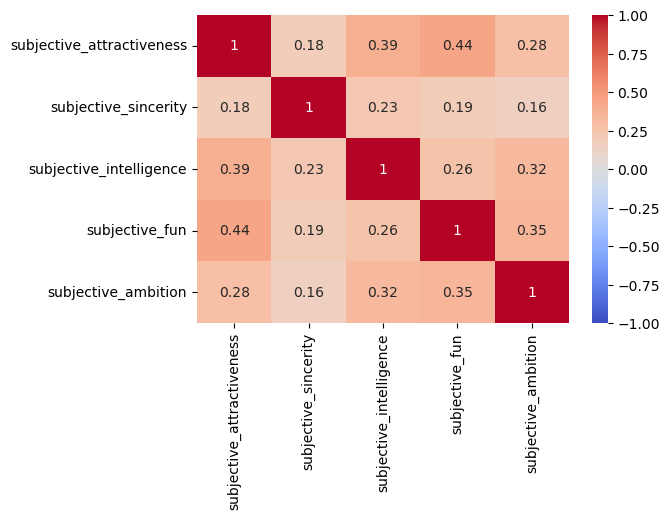

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(subj.corr(), vmin=-1, cmap='coolwarm', annot=True);

# There appears to be medium positive correlation between most of these features.

### 4) PCA

#### 4a) Transform `subj` into its principal components
Instantiate and fit a principal components model object. Transform the `subj` data into its principal components. Note that since we're transforming the full dataset, you'll end up with a matrix of the same size as `subj`. To do this, follow the directions exactly:

1. Standard scale your `subj` data frame and call this scaled variable `X`.
2. Convert `X` into its principal components by using `PCA()`. Call the transformed data frame `Z`. These are your features converted into their principal components.

In [12]:
sc = StandardScaler()
pc = PCA()

X = sc.fit_transform(subj)
Z = pc.fit_transform(X)

#### 4b) What is the correlation between PC1 and PC2?

_Hint:_ The first principal component (PC1) is the first column of `Z` and PC2 is the second.

In [13]:
pc1 = Z[:, 0]
pc2 = Z[:, 1]

In [14]:
# Zero!
np.correlate(pc1, pc2)

array([-5.2846616e-14])

Next, show the correlation matrix of `Z`. What do you notice about its structure?

_Hint:_ You'll need to convert `Z` into a dataframe to use `.corr()` easily.

_Hint 2:_ Round the whole matrix to 4 decimal points to see it clearly!

In [15]:
np.round(pd.DataFrame(Z).corr(), 4)

,0,1,2,3,4
0,1.0,-0.0,0.0,0.0,-0.0
1,-0.0,1.0,-0.0,0.0,-0.0
2,0.0,-0.0,1.0,0.0,-0.0
3,0.0,0.0,0.0,1.0,0.0
4,-0.0,-0.0,-0.0,0.0,1.0


**Answer:** The principal components are all uncorrelated with eachother! This is true by definition - the whole point of PCA is to get decorrelated features of decreasing importance.

#### 4c) What is the dot product between PC1 and PC2?

_Hint:_ There are several ways to compute the dot product between two vectors:

1. `np.sum(u * v)`
2. `np.dot(u, v)`
3. `u @ v`

In [16]:
# Also zero! The vectors are orthogonal
pc1 @ pc2

-5.284661597215745e-14

#### 4d) Screeeee!
Plot the "scree plot" for your explained variances. That is, the x-axis is the principal component number, and the y-axis is its explained variance.

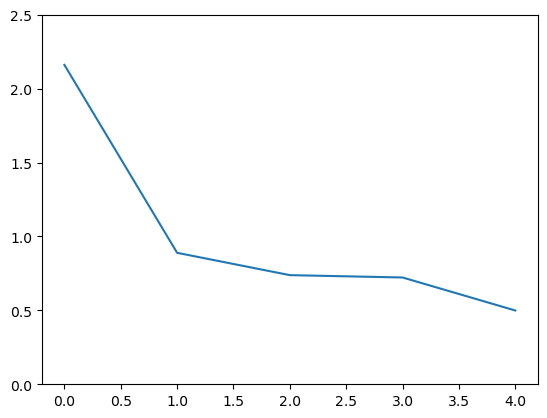

In [17]:
plt.plot(pc.explained_variance_)
plt.ylim(0, 2.5);

#### 4e) Computing the transformations by hand
Take the `.components_` property of your principal components object and assign it to a variable `V`. Compute $XV^T$ and confirm it's the same as `Z`.

In [18]:
V = pc.components_

In [19]:
(X @ V.T)[:5, :]

array([[ 0.673942  ,  0.03439955, -0.10382612, -0.35798348,  0.57693667],
       [ 1.35044583,  2.02341707, -2.13879048,  1.07112465,  1.64483811],
       [-0.94967947, -0.27146457, -0.03924025,  0.28967741, -0.18508884],
       [ 0.18027926,  0.57245653, -0.73567524, -1.23416221, -0.05104433],
       [ 1.31095851,  2.8363581 ,  2.16499567,  1.76020932,  0.75813709]])

In [20]:
Z[:5, :]

array([[ 0.673942  ,  0.03439955, -0.10382612, -0.35798348,  0.57693667],
       [ 1.35044583,  2.02341707, -2.13879048,  1.07112465,  1.64483811],
       [-0.94967947, -0.27146457, -0.03924025,  0.28967741, -0.18508884],
       [ 0.18027926,  0.57245653, -0.73567524, -1.23416221, -0.05104433],
       [ 1.31095851,  2.8363581 ,  2.16499567,  1.76020932,  0.75813709]])

In [21]:
np.sum(np.abs((X @ V.T) - Z))

2.0016880405808457e-12

#### 4f) PC1 make-up
The first column of $V^T$ (ie, the first row of $V$) is what determines how much of each feature goes into the first component. Take a look at the first column of $V^T$. What variables make up PC1 the most?

In [22]:
loading1 = V.T[:, 0]

pd.DataFrame({
    'names': subj.columns,
    'loadings': np.abs(loading1)
})

,names,loadings
0,subjective_attractiveness,0.501894
1,subjective_sincerity,0.315290
2,subjective_intelligence,0.467071
3,subjective_fun,0.483864
4,subjective_ambition,0.443187


**Answer:** It actually looks like the variables are nearly equally represented, with maybe sincerity being the least represented.

#### 4g) PC2 make-up
Now do the same for PC2. What do you see?

In [23]:
loading2 = V.T[:, 1]

pd.DataFrame({
    'names': subj.columns,
    'loadings': np.abs(loading2)
})

,names,loadings
0,subjective_attractiveness,0.218260
1,subjective_sincerity,0.909060
2,subjective_intelligence,0.097690
3,subjective_fun,0.274010
4,subjective_ambition,0.203342


**Answer:** Sincerity is the most represented in PC2!

### 5) Modeling
Use all of the steps we've learned in our class to create a model that predicts `like_reading`. To have done this "correctly", you must account for all of the following considerations:

* You must do a train-test split
* You must set up a pipeline that ends with conducting a linear regression
* You must set up a gridsearch on this pipeline that searches over the number of PCs to use
* You must fit your gridsearch _only on the training data_. 
    - _Note:_ You're using all available features here. Make sure not to include your y-variable as an x-variable!
* Finally, you must re-fit your pipeline using the number of PCs you have decided upon (note this is maybe not the number of PCs grid search as picked for you! See below.)
* What is the $R^2$ score on the testing data for your final model?

Note that `GridSearchCV` will find the best value of the number of PCs based on some scoring metric (probably the $R^2$). Remember that the goal of using PCA is to be as _parsimonious_ as possible with our modeling. That is, we want to use as few PCs as is reasonable to still get a "good enough" model. So, the GridSearch-optimal $k$ might not be the value of $k$ you want to use!

In [24]:
X = sd.drop(columns=['subject_id', 'wave', 'like_reading'])
y = sd['like_reading']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2023)

In [25]:
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('pc', PCA()),
    ('lr', LinearRegression())
])

pgrid = {'pc__n_components': np.arange(1, 22)}

gs = GridSearchCV(pipe, pgrid)

In [26]:
gs.fit(X_train, y_train);

In [27]:
df_gs = pd.DataFrame(gs.cv_results_)

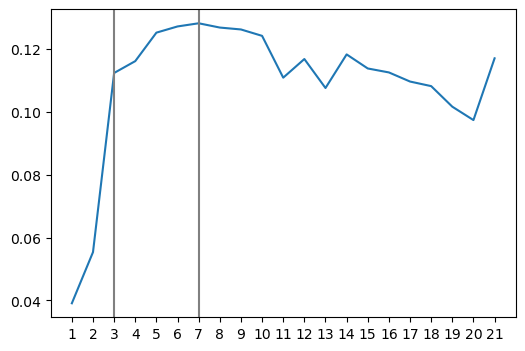

In [28]:
# Student answers here are actually pretty sensitive to the random seed during
# train-test splitting (ie, this model is bad and unstable). When considering their answers,
# however, notice in my solution that k = 3 and k = 7 yield basically the same score. It's
# totally feasible to just use 3 here. But the student can use either 3 or 7 reasonably.
plt.figure(figsize=(6, 4))
plt.plot(df_gs.param_pc__n_components, df_gs.mean_test_score)
plt.xticks(pgrid['pc__n_components'])
plt.axvline(3, c='grey');
plt.axvline(7, c='grey');

In [29]:
pipe.set_params(pc__n_components=3)

# pipe = Pipeline([
#     ('sc', StandardScaler()),
#     ('pc', PCA()),
#     ('lr', LinearRegression())
# ])

pipe.fit(X_train, y_train)

Pipeline(steps=[('sc', StandardScaler()), ('pc', PCA(n_components=3)),
                ('lr', LinearRegression())])

In [30]:
# Not great!
pipe.score(X_test, y_test)

0.006693668454305857